In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.formula.api as smf


In [2]:
obs = pd.read_csv("data/55_Hare_Data_2012.txt")

In [6]:

obs.head()
obs.info()
obs['date'] = pd.to_datetime(obs['date'])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3380 entries, 0 to 3379
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        3380 non-null   object 
 1   time        264 non-null    object 
 2   grid        3380 non-null   object 
 3   trap        3368 non-null   object 
 4   l_ear       3332 non-null   object 
 5   r_ear       3211 non-null   object 
 6   sex         3028 non-null   object 
 7   age         1269 non-null   object 
 8   weight      2845 non-null   float64
 9   hindft      1633 non-null   float64
 10  notes       243 non-null    object 
 11  b_key       3333 non-null   float64
 12  session_id  3380 non-null   int64  
 13  study       3217 non-null   object 
dtypes: float64(3), int64(1), object(10)
memory usage: 369.8+ KB


In [8]:
obs['age'].value_counts(dropna= False)

age
NaN          2111
A             564
J             267
a             183
j             128
1/2/2013       21
1/4/2013       21
3/4/2013       18
1              12
U              11
?              10
a 3/4 yr.       4
2 yrs.          3
u               3
A 3/4           2
1.5             2
3.5 yrs.        2
2.25 yrs        2
1 yr.           2
1 yr            2
a 1 yr.         2
A 1.5           1
2.5 yrs         1
3 yrs.          1
a 2 yrs.        1
J 3/4           1
2 yrs           1
A 1/2           1
a 1 yr          1
1.25            1
3.25 yrs.       1
Name: count, dtype: int64

When you make a decision, document it. 
We will keep all heare with a j as juvinile, and all hares with a as an adult.

In [17]:
# Update age values to juvenile and adult for observations where 'a' and 'j' are included
obs.loc[obs['age'].str.contains('j', case= False, na=False), 'age'] = 'juvenile'
obs.loc[obs['age'].str.contains('a', case= False, na=False), 'age'] = 'adult'

# Filter for confirmed observtions ofd juvenile and adult hares 
obs_juv_adult = obs[obs['age'].isin(['juvenile', 'adult'])].copy()
print('Number of juvenile and adult hasre obsetvations(captures):', len(obs_juv_adult))

Number of juvenile and adult hasre obsetvations(captures): 1155


In [18]:
# Extract year in which each observation happened 
obs_juv_adult['year'] = obs_juv_adult['date'].dt.year

In [24]:
# Count observations per year and age, then move age values into columns
obs_per_year = obs_juv_adult.groupby(['year', 'age']).size().unstack()

In [25]:
obs_per_year

age,adult,juvenile
year,,
1999,150.0,126.0
2000,159.0,67.0
2001,72.0,22.0
2002,3.0,NaN
2003,1.0,18.0
2004,NaN,8.0
2005,95.0,48.0
2006,101.0,15.0
2007,13.0,5.0


<Axes: title={'center': 'Juvenile and adult snowshoe hare captures per year'}, xlabel='Year', ylabel='Number of captures'>

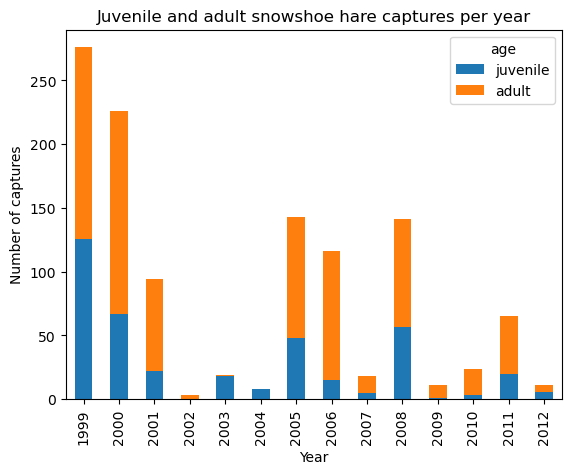

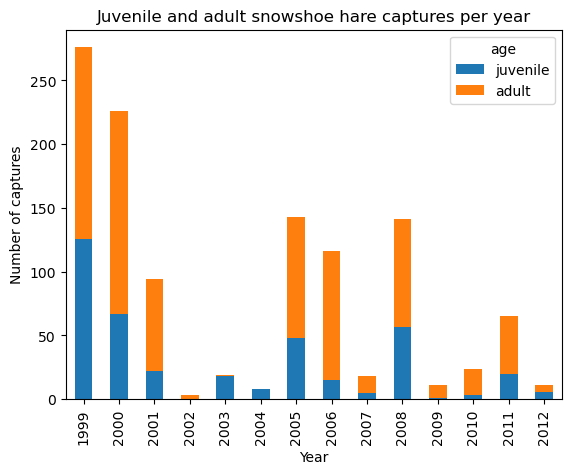

In [31]:
obs_per_year[['juvenile', 'adult']].plot(kind='bar',
                                        stacked= True, 
                                        title= 'Juvenile and adult snowshoe hare captures per year', 
                                        xlabel='Year', 
                                        ylabel= 'Number of captures')

Always ask questions on your data: we are unusre of the efforts within those years. 

## Ploting with matplotlib

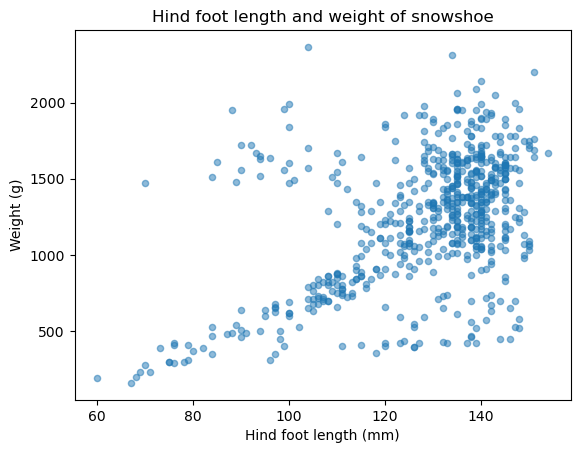

In [35]:
# Initialize an empty figure and axes 
fig, ax = plt.subplots()

# Add scatterplot of hsres data to our figures axes 
obs_juv_adult.plot(kind= 'scatter', x='hindft', y='weight', ax=ax, alpha=0.5)

#Update axes 
ax.set_title('Hind foot length and weight of snowshoe')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')
#display figure
plt.show()

## Linear regression 
for pur analysis we want to investigate possibe relations between hind foot and wright of juvenioe hares.

In [39]:
juv_w_ht = juveniles_weight_hindfoot = obs_juv_adult[obs_juv_adult['age'] == 'juvenile'].dropna(subset=['hindft', 'weight'])

Number of obervtions 265


<Axes: xlabel='hindft', ylabel='weight'>

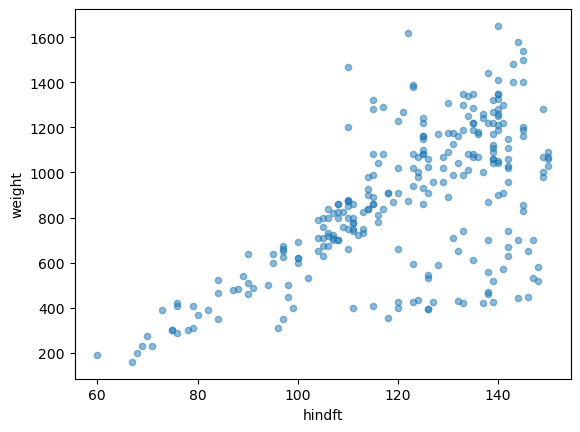

In [42]:
print('Number of obervtions', len(juv_w_ht))
juv_w_ht.plot.scatter(x='hindft', y='weight', alpha=0.5)

In [44]:
# Fit a model: weight explained by hind foot length
model = smf.ols('weight~hindft', data= juv_w_ht).fit()

In [45]:
model.params

Intercept   -352.771986
hindft        10.092240
dtype: float64

In [48]:
# Retrieve parameters
intercept= model.params['Intercept']
print('y-int:', intercept)

slope= model.params['hindft']
print('slope:', slope)

y-int: -352.7719856464058
slope: 10.092239638623012


a. The biological meaning of the y-int, it means that if a hare does not have a hindfoot it would weigh -352

b. The estimated change in weight for each milimeter increase is about 10 grams. 

c. 

In [49]:
print('R^2:', model.rsquared)

R^2: 0.3871164783665738


R^2 is the coefficient of determination. It is between 0 and 1. R^2=1 is a perfect fir of the modelt to the data. 
We interpret it as the proportion of varieance in the response that is explained by the peast squares line with the predictor variable. 

In [59]:
# Smallest and the largest hinf ft leangths 
x_start= juv_w_ht['hindft'].min()
x_end= juv_w_ht['hindft'].max()

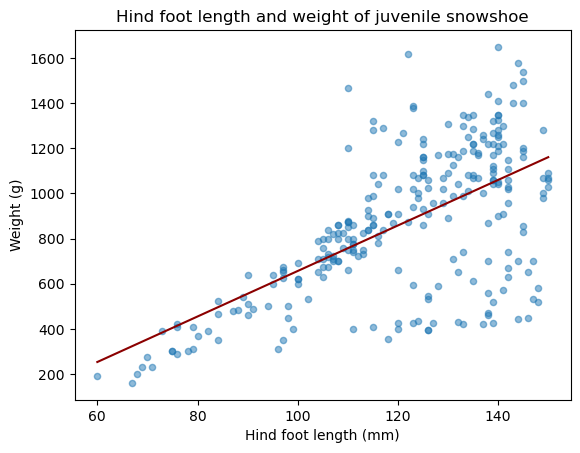

In [61]:
# Initialize an empty figure and axes 
fig, ax = plt.subplots()

# Add scatterplot of hsres data to our figures axes 
juv_w_ht.plot(kind= 'scatter', x='hindft', y='weight', ax=ax, alpha=0.5)

# Add regression line to the axe 
ax.plot([x_start, x_end], 
        [intercept + slope*x_start, intercept + slope*x_end],
        color='darkred')

#Update axes 
ax.set_title('Hind foot length and weight of juvenile snowshoe')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Weight (g)')
#display figure
plt.show()

In [62]:
model.resid

108    -523.850209
109    -609.864845
110    -655.510522
111    -397.835573
112    -549.403647
           ...    
3355    -46.820937
3359    117.625625
3360    117.625625
3367   -276.175259
3369    -37.189895
Length: 265, dtype: float64

<Axes: title={'center': 'Distribution of residuals'}, xlabel='Residual (g)', ylabel='Frequency'>

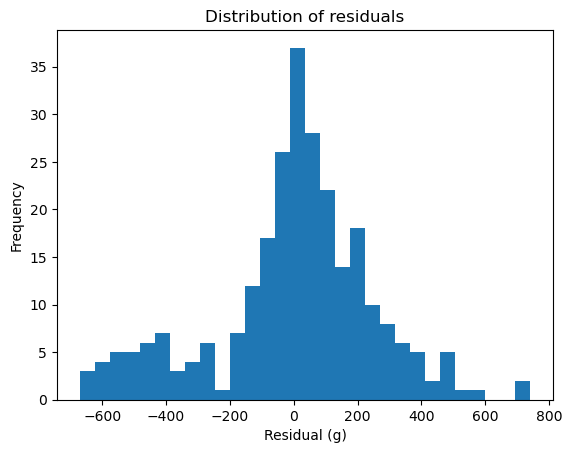

In [63]:
model.resid.plot(kind='hist', 
                 bins=30, 
                 title='Distribution of residuals', 
                 xlabel='Residual (g)')

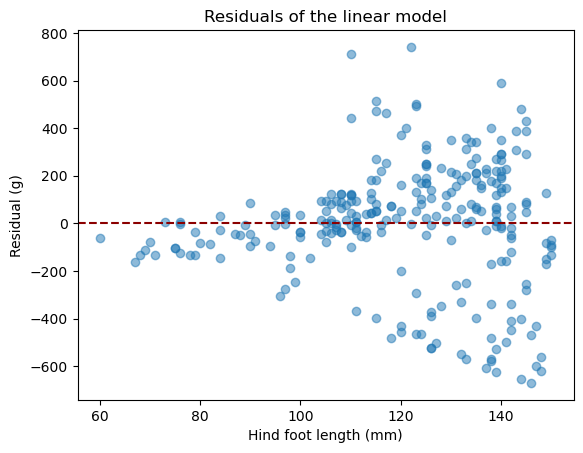

In [65]:
# Initialize empty figure and axes
fig, ax = plt.subplots()

# Add residuals to axes
ax.scatter(juv_w_ht['hindft'], model.resid, alpha=0.5)

# Add reference line at 0
ax.axhline(0, color='darkred', linestyle='--')

# Update axes
ax.set_title('Residuals of the linear model')
ax.set_xlabel('Hind foot length (mm)')
ax.set_ylabel('Residual (g)')

# Display figure
plt.show()